# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [6]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

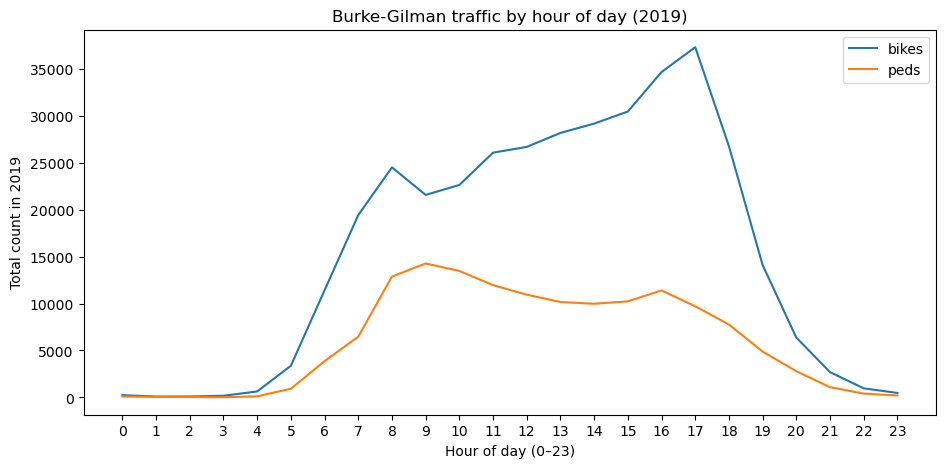

In [7]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

In [8]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)

df["total"] = df["bikes"] + df["peds"]

# average count for each hour of day
hourly = df.groupby("hour")[["bikes", "peds", "total"]].mean()

print("Busiest hours (bikes + peds):")
print(hourly.sort_values("total", ascending=False).head(3))
print("\nQuietest hours:")
print(hourly.sort_values("total").head(3))

# busiest 3-hour stretch - rolling window sums 3 consecutive hours
window = hourly["total"].rolling(3).sum()
end = window.idxmax()
print(f"\nBusiest 3-hour stretch: {end-2}:00 to {end}:59")

Busiest hours (bikes + peds):
           bikes       peds       total
hour                                   
17    102.167123  26.591781  128.758904
16     94.926027  31.213699  126.139726
15     83.405479  28.032877  111.438356

Quietest hours:
         bikes      peds     total
hour                              
2     0.282192  0.120548  0.402740
1     0.271233  0.158904  0.430137
3     0.490411  0.065753  0.556164

Busiest 3-hour stretch: 15:00 to 17:59


**Your Q1 answer:**

*I defined “busy” as the average count of bikes and pedestrians combined per hour, and I also looked at the best 3-hour stretch, since people use the trail over a window of time and not at a single instant. I used averages instead of totals so that days with missing sensor hours don’t make an hour look artificially quiet. By this measure the trail is busiest from 3 p.m. to 6 p.m., peaking at 5 p.m. with about 129 people per hour, while the quietest hours are 1 to 3 a.m., at roughly 0.4 to 0.6 people per hour. The busiest hour sees about 300 times the traffic of the quietest, and the afternoon peak is overwhelmingly bikes (about 102 per hour at 5 p.m. versus about 27 pedestrians), so a combined count mostly reflects cyclists. That the peak falls in the late afternoon suggests many people use the trail around the end of the workday, though this alone can’t separate commuting from after-work recreation.*

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

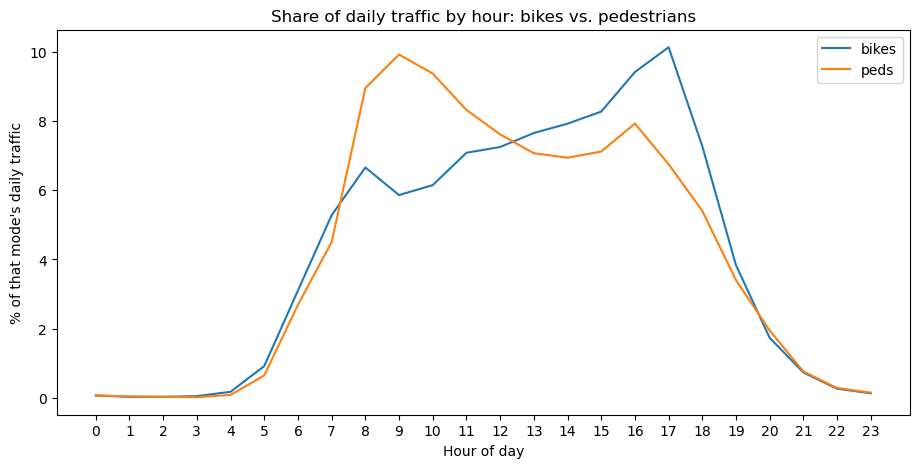

Peak hour, bikes: 17
Peak hour, peds:  9


In [9]:
# Your code for Q2

# converting each mode to % of its own daily total to compare shapes
share = hourly[["bikes", "peds"]] / hourly[["bikes", "peds"]].sum() * 100

share.plot(figsize=(11, 5))
plt.title("Share of daily traffic by hour: bikes vs. pedestrians")
plt.xlabel("Hour of day")
plt.ylabel("% of that mode's daily traffic")
plt.xticks(range(24))
plt.show()

print("Peak hour, bikes:", hourly["bikes"].idxmax())
print("Peak hour, peds: ", hourly["peds"].idxmax())

**Your Q2 answer:**

*Cyclists and pedestrians use the trail at different times of day. Bikes peak at 5 p.m. (hour 17), in the late afternoon, while pedestrians peak at 9 a.m. (hour 9), in the morning. To compare the shapes fairly, I converted each mode to a share of its own daily total, since cyclists far outnumber pedestrians and raw counts would hide the difference in timing. One plausible explanation is that cyclists are riding home or out for an after-work ride, while pedestrians are walking, jogging, or walking dogs earlier in the day, when they have more flexibility. This is a hypothesis: the counter records bodies passing by, not why they are there.*

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

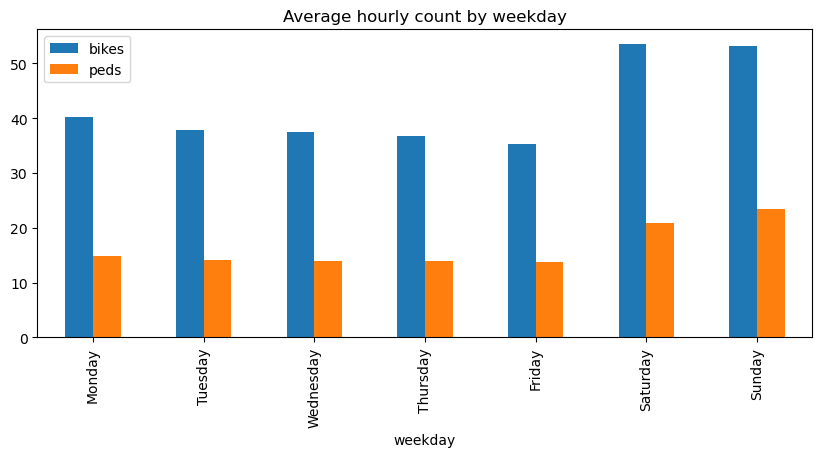

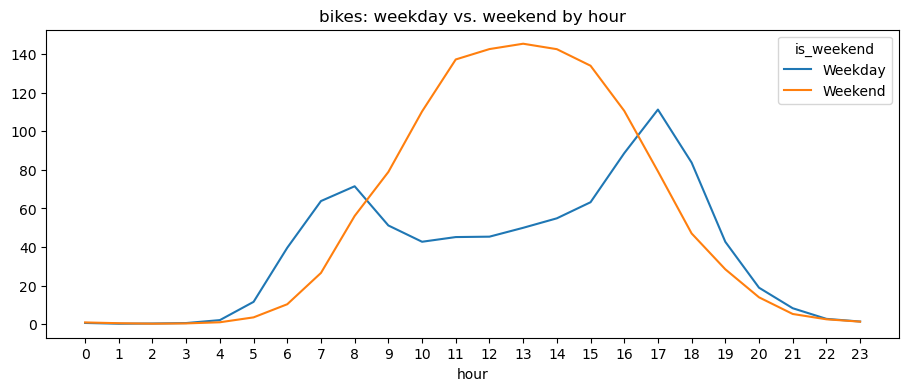

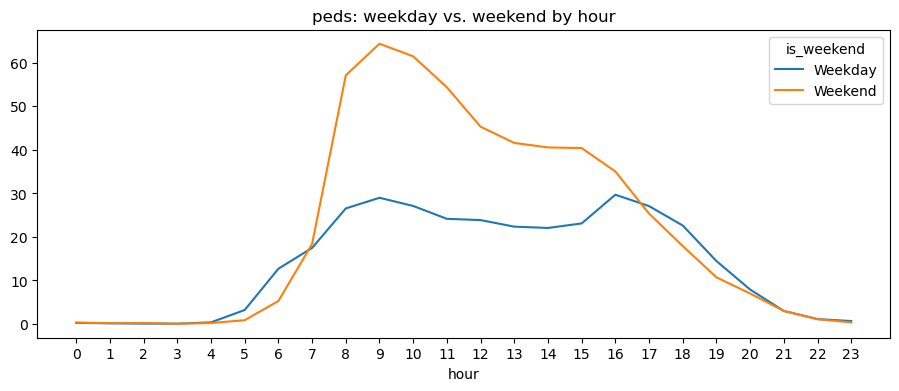

In [10]:
# Your code for Q3

df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"])

# average hourly count by day of week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]
by_day = df.groupby("weekday")[["bikes", "peds"]].mean().reindex(day_order)
by_day.plot(kind="bar", figsize=(10, 4), title="Average hourly count by weekday")
plt.show()

# hourly profile, weekday vs. weekend, one plot per mode
profile = df.groupby(["is_weekend", "hour"])[["bikes", "peds"]].mean()
for mode in ["bikes", "peds"]:
    p = profile[mode].unstack(0).rename(columns={False: "Weekday", True: "Weekend"})
    p.plot(figsize=(11, 4), title=f"{mode}: weekday vs. weekend by hour")
    plt.xticks(range(24))
    plt.show()

**Your Q3 answer:**

*I defined a commuting pattern as two sharp weekday peaks near the start and end of the workday, with a dip in between, that is weaker or absent on weekends. A recreational pattern would instead be a single broad midday hump, with higher volume on weekends. Cyclists show the commuting signature: on weekdays, bike traffic peaks at about 72 per hour at 8 a.m. and about 111 at 5 p.m., with a dip to about 43 at 10 a.m., while on weekends the two peaks disappear into one broad midday hump of about 145. At the same time, the trail is busier overall on weekends (roughly 53 bikes per hour versus 35 to 40 on weekdays, and about 22 pedestrians versus 14), and pedestrians look recreational, with a sharp weekend peak at 9 a.m. and only weak weekday bumps. So the Burke-Gilman serves both purposes: commuting is clearly present, especially among cyclists, but recreation drives the highest volumes. The counter records bodies passing, not trip purpose, so this is a pattern consistent with commuting, not proof of it.*

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

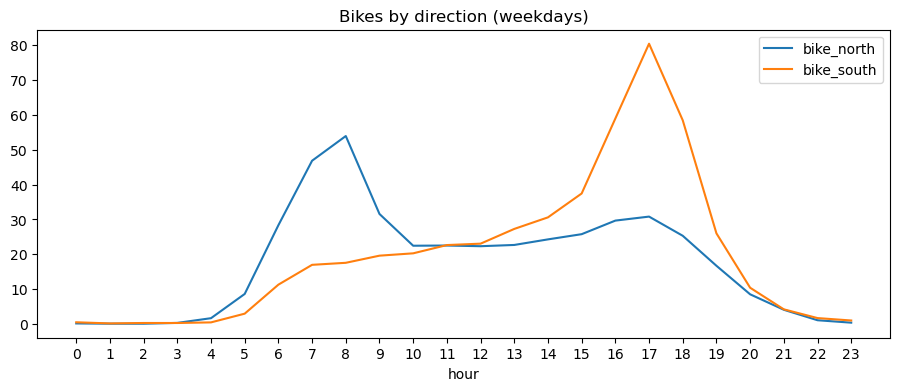

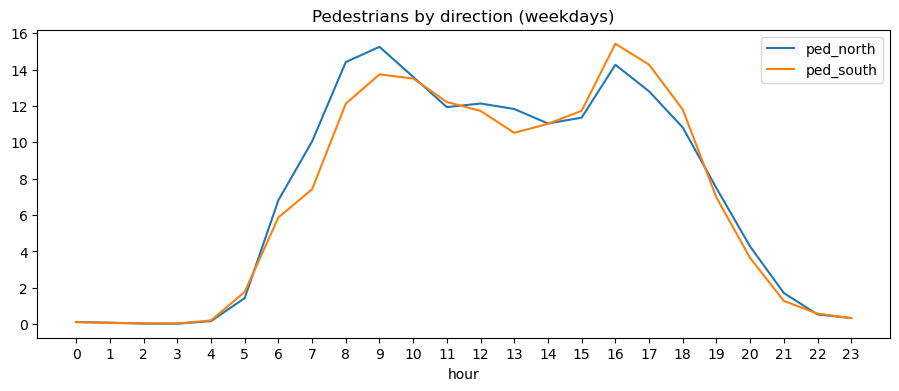

hour
0     -0.3
1     -0.1
2     -0.2
3      0.0
4      1.2
5      5.7
6     17.1
7     29.9
8     36.4
9     12.0
10     2.2
11    -0.1
12    -0.7
13    -4.6
14    -6.3
15   -11.7
16   -29.3
17   -49.7
18   -33.2
19    -9.3
20    -1.9
21    -0.1
22    -0.6
23    -0.6
dtype: float64


In [11]:
# Your code for Q4

weekdays = df[~df["is_weekend"]]

dirs = weekdays.groupby("hour")[["bike_north", "bike_south",
                                 "ped_north", "ped_south"]].mean()

dirs[["bike_north", "bike_south"]].plot(figsize=(11, 4), title="Bikes by direction (weekdays)")
plt.xticks(range(24)); plt.show()

dirs[["ped_north", "ped_south"]].plot(figsize=(11, 4), title="Pedestrians by direction (weekdays)")
plt.xticks(range(24)); plt.show()

# net flow - positive = more northbound, negative = more southbound
print((dirs["bike_north"] - dirs["bike_south"]).round(1))

**Your Q4 answer:**

*On weekdays, cyclists show a sharp directional flip. In the morning, northbound bikes dominate: at 8 a.m. there are about 54 northbound versus about 18 southbound per hour (a net of about +36 north). In the evening the flow reverses, with southbound bikes peaking at about 80 per hour at 5 p.m. against about 31 northbound (a net of about -50). Between roughly 10 a.m. and noon, the two directions are nearly equal. This tide-like flow is what you’d expect from commuters who travel one way to work in the morning and return the opposite way in the evening, so it is strong evidence that many cyclists use the trail for commuting, with home on the south side of this counter and destinations on the north side. Pedestrians behave differently: their northbound and southbound counts stay within a couple of people of each other all day, which suggests walks that go out and come back, not one-way trips to a destination. Together, this indicates that cyclists use the trail as a commuting route, while pedestrians mostly use it for recreation or short local trips.*

In [12]:
# Outlier Check 

print(df.nlargest(8, "peds")[["date", "peds", "bikes"]])
print(df.nlargest(8, "bikes")[["date", "peds", "bikes"]])
print(df.groupby(["is_weekend", "hour"])["peds"].median().unstack(0).loc[[7, 8, 9, 10]])

                    date  peds  bikes
8023 2019-12-01 08:00:00  1752     12
8024 2019-12-01 09:00:00   999     10
8025 2019-12-01 10:00:00   170     15
2623 2019-04-20 08:00:00   169    105
5170 2019-08-04 11:00:00   161    304
2481 2019-04-14 10:00:00   141     84
3296 2019-05-18 09:00:00   132    181
5169 2019-08-04 10:00:00   131    252
                    date  peds  bikes
5621 2019-08-23 06:00:00    46   1039
5622 2019-08-23 07:00:00    42    714
3514 2019-05-27 11:00:00    62    410
3516 2019-05-27 13:00:00    45    405
3515 2019-05-27 12:00:00    59    379
3517 2019-05-27 14:00:00    58    361
2149 2019-03-31 14:00:00    66    339
2988 2019-05-05 13:00:00    60    327
is_weekend  False  True 
hour                    
7            16.0   16.0
8            26.0   41.0
9            28.0   53.5
10           25.0   59.0


## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*One limitation is that the counter contains extreme one-off hours that can distort averages. On Sunday, December 1, 2019, it recorded 1,752 pedestrians at 8 a.m. and 999 at 9 a.m., while 75% of all hours had 27 or fewer, and bike counts in those hours were low. This looks like an organized event rather than ordinary use, though the data cannot confirm that or rule out a sensor error. Because I used averages, this one morning inflated the weekend pedestrian curve; using medians, the weekend peak was still rising at 10 a.m. rather than peaking at 9. Someone who trusted the averages uncritically could mistake a single event for a regular weekend pattern.*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.